# Лабораторная работа 1. Метод ближайших соседей

Для объекта с неизвестным типом здания ищем дома с похожими характеристиками в Ames. Для аукциона прогнозируем длительность проверки по измерениям для похожих параметров запроса и лимитов участников. В обоих случаях расстояния считаем в пространстве подготовленных числовых и категориальных признаков.

## Данные и разбиение выборки

In [1]:
# Указываем входные признаки и параметры эксперимента.
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SEED = 42
AMES_NUM = [
    "Lot Area", "Lot Frontage", "Year Built", "Overall Qual", "Overall Cond",
    "Gr Liv Area", "1st Flr SF", "2nd Flr SF", "Total Bsmt SF", "Full Bath",
    "Half Bath", "Bedroom AbvGr", "Kitchen AbvGr", "TotRms AbvGrd",
    "Garage Area", "Garage Cars",
]
AMES_CAT = ["Neighborhood", "House Style", "Foundation", "Roof Style"]
CAPACITIES = [f"process.b{i}.capacity" for i in range(1, 5)]
AUCTION_CAT = ["property.product", "property.winner"]
AUCTION_FEATURES = [*CAPACITIES, "property.price", *AUCTION_CAT]
RUNTIME = "verification.time"
TASKS = ("classification", "regression")
TASK_NAME = {"classification": "Классификация", "regression": "Регрессия"}



LAB = 1
ALGORITHM = "KNN"

In [2]:
# Читаем данные и формируем обучающие, проверочные и тестовые выборки.
@dataclass
class Sample:
    X: pd.DataFrame
    y: np.ndarray
    identifiers: np.ndarray
    train: np.ndarray
    test: np.ndarray
    folds: list
    groups: np.ndarray | None = None


def load_samples():
    """Индексы train/test и индексы фолдов относятся к строкам исходной таблицы."""
    ames = pd.read_csv(ROOT / "data/AmesHousing.csv")
    auction = pd.read_csv(ROOT / "data/auction_verification.csv")
    if not ames["PID"].is_unique:
        raise ValueError("Ожидались уникальные идентификаторы объектов")
    if ames["Bldg Type"].isna().any() or auction[RUNTIME].isna().any():
        raise ValueError("В исходной разметке есть пропуски")
    y = ames["Bldg Type"].eq("1Fam").astype(int).to_numpy()
    X = ames[AMES_NUM + AMES_CAT].copy()
    train, test = train_test_split(
        np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED,
    )
    splits = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    folds = [(train[a], train[b]) for a, b in splits.split(X.iloc[train], y[train])]
    classification = Sample(X, y, ames["PID"].to_numpy(), train, test, folds)

    # Лимиты четырёх участников задают конфигурацию одной модели аукциона.
    X = auction[AUCTION_FEATURES].copy()
    X[AUCTION_CAT] = X[AUCTION_CAT].astype(str)
    y = auction[RUNTIME].to_numpy(dtype=float) / 1000  # из миллисекунд в секунды
    groups = auction.groupby(CAPACITIES, sort=True).ngroup().to_numpy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train, test = next(splitter.split(X, y, groups))
    splits = GroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    folds = [(train[a], train[b]) for a, b in splits.split(X.iloc[train], y[train], groups[train])]
    for a, b in [(train, test), *folds]:
        assert not set(groups[a]) & set(groups[b])
    regression = Sample(X, y, np.arange(1, len(auction) + 1), train, test, folds, groups)
    return {"classification": classification, "regression": regression}



samples = load_samples()

In [3]:
# Формируем признаки и обучаем преобразования внутри каждого разбиения.
def feature_frame(X, task, mode):
    """Построчные преобразования используют только поля конкретного объекта."""
    if mode == "base":
        return X
    if mode != "extra":
        raise ValueError(f"Неизвестный набор признаков {mode}")
    result = X.copy()
    if task == "classification":
        lot = X["Lot Area"].replace(0, np.nan)
        above_ground = X["Gr Liv Area"].replace(0, np.nan)
        result["Жилая площадь / участок"] = X["Gr Liv Area"] / lot
        result["Гараж / жилая площадь"] = X["Garage Area"] / above_ground
    else:
        result["Сумма лимитов"] = X[CAPACITIES].sum(axis=1)
        result["Произведение по лимитам"] = (X[CAPACITIES] + 1).prod(axis=1)
    return result


def design(sample, task, mode, train, evaluate):
    """Обучаем заполнение пропусков, шкалу и словарь категорий внутри каждого разбиения."""
    frame = feature_frame(sample.X, task, mode)
    cats = AMES_CAT if task == "classification" else AUCTION_CAT
    nums = [column for column in frame.columns if column not in cats]
    transformers = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums)]
    if cats:
        encoder = make_pipeline(
            SimpleImputer(strategy="constant", fill_value="(пропуск)"),
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        )
        transformers.append(("cat", encoder, cats))
    transform = ColumnTransformer(transformers)
    return transform.fit_transform(frame.iloc[train]), transform.transform(frame.iloc[evaluate])

## Выбор данных и постановка задач

**Ames Housing.** Городскому реестру и каталогу объявлений может понадобиться восстановить пропущенный тип здания по карточке объекта. В 2 930 строках есть исходная категориальная разметка `Bldg Type`. Метка 1 соответствует отдельно стоящему односемейному дому (`1Fam`), а метка 0 объединяет дуплексы (`Duplex`), таунхаусы (`Twnhs`, `TwnhsE`) и дома, переоборудованные под две семьи (`2fmCon`). В модели участвуют 16 числовых и четыре категориальных признака, в том числе площадь, год постройки, число комнат, район и фундамент. Идентификаторы `PID` и `Order`, целевой столбец и код `MS SubClass`, в котором уже зашифрован тип застройки, исключены. Цена продажи и поля, описывающие сделку, также исключены: для классификации достаточно карточки здания. [Ames Housing на Kaggle](https://www.kaggle.com/datasets/shashanknecrothapa/ames-housing-dataset)

**Auction Verification.** Каждый из 2 043 примеров описывает проверку возможного исхода многораундового аукциона. Прогноз длительности до запуска помогает планировать очередь проверок. Пять числовых входов — лимиты четырёх участников (`process.b1.capacity` … `process.b4.capacity`, сколько товаров максимум может выиграть каждый участник) и проверяемая цена `property.price`. Ещё два входа обозначают товар (`property.product`) и проверяемого кандидата в победители (`property.winner`, 0 — проверяется только цена). Их кодируем как категории. Цель — среднее время для данной комбинации входов. Авторы усреднили повторные измерения. Пересчитываем `verification.time / 1000` в секунды. Поле `verification.result` становится известно после проверки и исключено из входных данных. [Данные и описание полей, UCI](https://archive.ics.uci.edu/dataset/713/auction+verification) · [Пересчёт миллисекунд в секунды в коде авторов](https://github.com/Jakob-Bach/Analyzing-Auction-Verification/blob/master/run_evaluation.py) · [Как авторы усредняли повторные измерения](https://github.com/Jakob-Bach/Analyzing-Auction-Verification/blob/master/prepare_dataset.py#L53-L72)

### Разбиение и пропуски

Ames делим с сохранением долей классов. В Auction Verification одна и та же четвёрка лимитов встречается в проверках разных товаров, кандидатов и цен. Группируем по четвёрке лимитов: 19 из 24 групп попадают в обучение, пять — в тест. Все строки каждой группы также остаются вместе при кросс-валидации. Так оцениваем время при новых конфигурациях лимитов. Подбор модели и изучение связей выполняем по обучающей части. Медианы заполнения, параметры стандартизации и словарь категорий в каждом фолде определяются заново по его обучающим строкам.

In [4]:
# Сверяем размеры таблиц и наличие пропусков в признаках обучения.
cls_sample, reg_sample = samples["classification"], samples["regression"]
ames_train = cls_sample.X.iloc[cls_sample.train].copy()
ames_train["Класс"] = cls_sample.y[cls_sample.train]
auction_train = reg_sample.X.iloc[reg_sample.train].copy()
auction_train["Время, с"] = reg_sample.y[reg_sample.train]
split_rows = []
missing_rows = []
for name, sample in [("Ames Housing", cls_sample), ("Auction Verification", reg_sample)]:
    split_rows.append([name, len(sample.X), sample.X.shape[1], len(sample.train), len(sample.test)])
    missing = sample.X.iloc[sample.train].isna().sum()
    for feature, count in missing[missing > 0].items():
        missing_rows.append([name, feature, count, round(100 * count / len(sample.train), 2)])
display(pd.DataFrame(split_rows, columns=["Данные", "Всего строк", "Признаков", "Обучение", "Тест"]))
display(pd.DataFrame(missing_rows, columns=["Данные", "Признак с пропусками", "Число пропусков", "% обучения"]))
print("Аукцион — уникальных конфигураций лимитов в обучении и тесте:",
      len(np.unique(reg_sample.groups[reg_sample.train])),
      len(np.unique(reg_sample.groups[reg_sample.test])))

,Данные,Всего строк,Признаков,Обучение,Тест
0,Ames Housing,2930,20,2344,586
1,Auction Verification,2043,7,1723,320


,Данные,Признак с пропусками,Число пропусков,% обучения
0,Ames Housing,Lot Frontage,395,16.85
1,Ames Housing,Total Bsmt SF,1,0.04
2,Ames Housing,Garage Area,1,0.04
3,Ames Housing,Garage Cars,1,0.04


Аукцион — уникальных конфигураций лимитов в обучении и тесте: 19 5


На обучении Ames больше всего пропусков у `Lot Frontage` (протяжённость участка вдоль улицы). Заполняем числовые пропуски медианой соответствующего обучающего фолда, чтобы сохранить строки для анализа. Во всех семи входных полях Auction Verification пропусков нет.

### Распределение целей

Доли классов помогают понять, сколько объектов каждого типа участвует в подборе модели. Для регрессии посмотрим, сколько длится типичная проверка и как часто встречаются более долгие запуски.

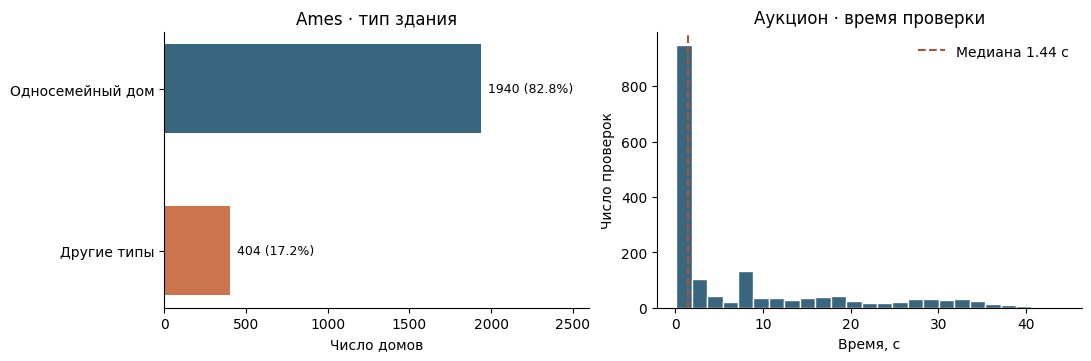

Время в секундах: минимум 0.079, квартиль 25% 0.58, медиана 1.44, квартиль 75% 11.18, максимум 44.13.


In [5]:
# Строим диаграмму частот и гистограмму только по обучающим целям.
labels = ["Другие типы", "Односемейный дом"]
counts = ames_train["Класс"].value_counts().reindex([0, 1], fill_value=0)
runtime = auction_train["Время, с"]
fig, (ax_class, ax_time) = plt.subplots(1, 2, figsize=(10.8, 3.5), layout="constrained")
bars = ax_class.barh(labels, counts, color=["#CA754E", "#38667F"], height=0.55)
ax_class.bar_label(bars, labels=[f"{v} ({v / counts.sum():.1%})" for v in counts],
                   padding=5, fontsize=9)
ax_class.set_xlim(0, counts.max() * 1.34)
ax_class.set(title="Ames · тип здания", xlabel="Число домов")
ax_time.hist(runtime, bins=25, color="#38667F", edgecolor="white")
ax_time.axvline(runtime.median(), color="#AE5431", linestyle="--",
                 label=f"Медиана {runtime.median():.2f} с")
ax_time.set(title="Аукцион · время проверки", xlabel="Время, с",
             ylabel="Число проверок")
ax_time.legend(frameon=False)
for ax in (ax_class, ax_time):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"Время в секундах: минимум {runtime.min():.3f}, квартиль 25% {runtime.quantile(.25):.2f}, "
      f"медиана {runtime.median():.2f}, квартиль 75% {runtime.quantile(.75):.2f}, "
      f"максимум {runtime.max():.2f}.")

В обучающей части Ames отдельно стоящие дома составляют 82,8%. Классификатор, всегда выбирающий этот класс, получит высокую долю верных ответов и пропустит все 404 объекта других типов. Поэтому основной показатель классификации — macro-F1 с одинаковым весом двух классов. Время половины проверок в обучении укладывается в 1,44 с, однако четверть требует как минимум 11,18 с. Самая долгая проверка заняла 44,13 с. Основная метрика MAE измеряет среднюю абсолютную ошибку прогноза в секундах. Дополнительная RMSE сильнее реагирует на крупные промахи.

### Связи с признаками

Сопоставим размеры участков и жилых помещений по типу здания, а для аукциона оценим ранговую корреляцию Спирмена между временем проверки, агрегатами лимитов и проверяемой ценой. Эти сравнения помогают обосновать гипотезы о полезных признаках для KNN.

In [6]:
# Сравниваем типичные площади и число кухонь, затем оцениваем связи с длительностью проверки.
by_type = ames_train.assign(Несколько_кухонь=ames_train["Kitchen AbvGr"].gt(1)).groupby("Класс")
areas = by_type[["Lot Area", "Gr Liv Area"]].median()
areas.columns = ["Медиана площади участка, фут²", "Медиана жилой площади, фут²"]
areas["Несколько кухонь над землёй, %"] = (100 * by_type["Несколько_кухонь"].mean()).round(1)
areas.index = labels
display(areas)
cap_cols = [f"process.b{i}.capacity" for i in range(1, 5)]
auction_factors = pd.DataFrame({
    "Сумма лимитов": auction_train[cap_cols].sum(axis=1),
    "Произведение четырёх (1 + лимит)": (auction_train[cap_cols] + 1).prod(axis=1),
    "Проверяемая цена": auction_train["property.price"],
    "Время, с": auction_train["Время, с"],
})
corr = auction_factors.corr(method="spearman")["Время, с"].drop("Время, с")
display(corr.rename("Корреляция Спирмена со временем").round(2).to_frame())

,"Медиана площади участка, фут²","Медиана жилой площади, фут²","Несколько кухонь над землёй, %"
Другие типы,4519.0,1339.0,23.0
Односемейный дом,9786.0,1462.0,0.4


,Корреляция Спирмена со временем
Сумма лимитов,0.51
Произведение четырёх (1 + лимит),0.56
Проверяемая цена,0.16


У отдельно стоящего дома медианный участок занимает 9 786 фут², у дома другого типа — 4 519 фут². Разница медианных жилых площадей меньше (1 462 и 1 339 фут²). Это даёт основание проверить отношение жилой площади к площади участка. В Auction Verification связь длительности с суммой лимитов (ρ = 0,51) и с произведением четырёх величин «1 + лимит» (ρ = 0,56) сильнее, чем с проверяемой ценой (ρ = 0,16). Произведение используем как показатель масштаба задачи; в наборе нет измерений фактического числа состояний. Проверим на обучающих фолдах, даёт ли добавление этих признаков снижение ошибки.

## Метрики и правила сравнения

В Ames основной показатель — **macro-F1**. Для каждого класса вычисляем гармоническое среднее точности и полноты, затем усредняем два результата с равными весами. Дополнительно приводим **accuracy** (долю верных ответов) и **balanced accuracy** (среднюю полноту классов).

Также рассчитываем **ROC-AUC** по вероятностям класса `1Fam`. Он показывает, насколько хорошо модель ранжирует два класса при разных порогах. Чем ближе ROC-AUC к 1, тем лучше.

В UCI минимизируем **MAE** — среднюю абсолютную ошибку длительности проверки в секундах. **RMSE** сильнее штрафует крупные ошибки. **R²** показывает, насколько хорошо прогнозы объясняют вариацию времени относительно константы, равной среднему значению тестовых целей. У R² возможны и отрицательные значения.

Для подбора используем **три фолда внутри обучения**. В Ames сохраняем доли классов; в UCI все запросы с одинаковыми четырьмя лимитами участников остаются вместе. Сравниваем средние значения macro-F1 и MAE по фолдам. При равенстве с точностью до 10⁻¹² остаётся первая из перечисленных конфигураций. После выбора переобучаем модель на всей обучающей части. Библиотечная и собственная версии получают одинаковые матрицы признаков в каждом режиме.

## Бейзлайн и гипотезы

Исходная модель берёт пять соседей с равными весами. Проверим три изменения по отдельности: увеличение числа соседей до 11, обратные веса по расстоянию и добавление производных признаков. Большая окрестность может сгладить шум, а обратные веса — усилить вклад самых близких аналогов. Производные признаки изменяют геометрию поиска. Затем проверим их совместное действие. Кандидатов сравним на одинаковых фолдах обучения.

Метка `base` означает исходные признаки. Числовые пропуски заполняются медианой, числовые признаки стандартизуются, категории кодируются индикаторами. Все параметры преобразований оцениваются на обучающей части соответствующего фолда. В режиме `extra` для Ames добавляются отношения жилой площади к площади участка и площади гаража к жилой площади, для аукциона — сумма четырёх лимитов и произведение их увеличенных на единицу значений. Произведение служит приближённым индикатором числа возможных комбинаций загрузки участников.

In [7]:
# Задаём семейство моделей и конфигурации до оценки на тесте.
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

def candidates(task):
    return [
        {"name": "5 соседей, равные веса", "features": "base",
         "params": {"n_neighbors": 5, "weights": "uniform"}},
        {"name": "11 соседей", "features": "base",
         "params": {"n_neighbors": 11, "weights": "uniform"}},
        {"name": "Обратные веса", "features": "base",
         "params": {"n_neighbors": 5, "weights": "distance"}},
        {"name": "Производные признаки", "features": "extra",
         "params": {"n_neighbors": 5, "weights": "uniform"}},
        {"name": "11 соседей, обратные веса и признаки", "features": "extra",
         "params": {"n_neighbors": 11, "weights": "distance"}},
    ]

def make_model(task, own, params):
    if own:
        return KNearestNeighbors(task, **params)
    model = KNeighborsClassifier if task == "classification" else KNeighborsRegressor
    return model(metric="euclidean", algorithm="brute", **params)

### Проверка гипотез на обучающих фолдах

В таблицах показаны индивидуальные оценки, среднее, выборочное стандартное отклонение и разность средних относительно базовой строки. Положительная разность полезна для macro-F1, отрицательная — для MAE.

In [8]:
# Задаём основные и дополнительные метрики.
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, r2_score, root_mean_squared_error, roc_auc_score,
)



PRIMARY = {"classification": "macro_f1", "regression": "mae"}
NAMES = {"macro_f1": "macro-F1", "mae": "MAE", "balanced_accuracy": "Balanced accuracy",
         "accuracy": "Accuracy", "roc_auc": "ROC-AUC", "rmse": "RMSE", "r2": "R²"}
IMPLEMENTATION = {"sklearn": "sklearn", "own": "Самостоятельная"}
STAGE = {"base": "Базовая", "selected": "Выбор по CV"}


def scores(task, y, prediction):
    if task == "classification":
        return {
            "macro_f1": f1_score(y, prediction, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y, prediction),
            "accuracy": accuracy_score(y, prediction),
        }
    return {"mae": mean_absolute_error(y, prediction),
            "rmse": root_mean_squared_error(y, prediction), "r2": r2_score(y, prediction)}

In [9]:
# Сравниваем конфигурации на трёх фолдах и выводим результаты.
def tune(samples, candidates, make_model, lab, algorithm):
    """CV только на обучающей выборке. При равенстве остаётся первый кандидат."""
    rows, chosen = [], {}
    for task in TASKS:
        sample = samples[task]
        options = candidates(task)
        matrices = {}
        task_rows = []
        for i, option in enumerate(options):
            mode = option["features"]
            if mode not in matrices:
                matrices[mode] = [design(sample, task, mode, a, b) for a, b in sample.folds]
            values = []
            for (a, b), (X_train, X_valid) in zip(sample.folds, matrices[mode]):
                model = make_model(task, False, option["params"]).fit(X_train, sample.y[a])
                prediction = model.predict(X_valid)
                values.append(scores(task, sample.y[b], prediction)[PRIMARY[task]])
            task_rows.append({
                "lab": lab, "algorithm": algorithm, "task": task,
                "configuration": option["name"], "features": mode,
                "params": json.dumps(option["params"], ensure_ascii=False, sort_keys=True),
                **{f"fold_{j}": value for j, value in enumerate(values, 1)},
                "mean": np.mean(values), "std": np.std(values, ddof=1),
                "selected": False, "base": i == 0,
            })
        means = np.array([row["mean"] for row in task_rows])
        best = max(means) if task == "classification" else min(means)
        idx = int(np.flatnonzero(np.isclose(means, best, atol=1e-12, rtol=0))[0])
        task_rows[idx]["selected"] = True
        chosen[task] = options[idx]
        rows.extend(task_rows)
    return pd.DataFrame(rows), chosen


def show_cv(frame):
    for task in TASKS:
        sub = frame[frame.task.eq(task)].copy()
        primary = NAMES[PRIMARY[task]]
        base = sub.loc[sub.base, "mean"].iloc[0]
        sub["delta"] = sub["mean"] - base
        header = f"{TASK_NAME[task]} · {primary} " + ("↑" if task == "classification" else "↓")
        display(Markdown(f"**{header}**"))
        table = sub[["configuration", "features", "fold_1", "fold_2", "fold_3",
                     "mean", "std", "delta", "selected"]].copy()
        table["selected"] = table["selected"].map({True: "✓", False: ""})
        table.columns = ["Конфигурация", "Признаки", "Фолд 1", "Фолд 2", "Фолд 3",
                         "Среднее", "SD", "Δ к базе", "Выбор"]
        display(table.set_index("Конфигурация").round(4))
        winner = sub[sub.selected].iloc[0]
        print(f"Выбор по среднему значению: {winner.configuration} ({primary} {winner['mean']:.4f}).")

In [10]:
# Отбираем конфигурации только по CV, затем фиксируем выбор для обеих реализаций.
base = {task: candidates(task)[0] for task in TASKS}
cv, selected = tune(samples, candidates, make_model, LAB, ALGORITHM)
show_cv(cv)

**Классификация · macro-F1 ↑**

,Признаки,Фолд 1,Фолд 2,Фолд 3,Среднее,SD,Δ к базе,Выбор
Конфигурация,,,,,,,,
"5 соседей, равные веса",base,0.9440,0.9206,0.9517,0.9387,0.0162,0.0000,
11 соседей,base,0.9333,0.9217,0.9367,0.9306,0.0079,-0.0082,
Обратные веса,base,0.9465,0.9232,0.9541,0.9412,0.0161,0.0025,
Производные признаки,extra,0.9517,0.9325,0.9471,0.9438,0.0100,0.0050,
"11 соседей, обратные веса и признаки",extra,0.9585,0.9325,0.9492,0.9467,0.0132,0.0080,✓


Выбор по среднему значению: 11 соседей, обратные веса и признаки (macro-F1 0.9467).


**Регрессия · MAE ↓**

,Признаки,Фолд 1,Фолд 2,Фолд 3,Среднее,SD,Δ к базе,Выбор
Конфигурация,,,,,,,,
"5 соседей, равные веса",base,5.8608,3.8918,2.9477,4.2334,1.4863,0.0000,
11 соседей,base,5.3738,3.8892,2.9354,4.0661,1.2288,-0.1673,
Обратные веса,base,5.8451,3.8496,2.9015,4.1987,1.5026,-0.0347,
Производные признаки,extra,4.4582,3.7929,2.9576,3.7362,0.7519,-0.4972,
"11 соседей, обратные веса и признаки",extra,4.4306,3.6763,3.0374,3.7148,0.6974,-0.5187,✓


Выбор по среднему значению: 11 соседей, обратные веса и признаки (MAE 3.7148).


## Библиотечная модель на отложенной выборке

Сначала оцениваем базовую модель sklearn, затем модель с конфигурацией, выбранной по CV.

In [11]:
# Считаем и выводим метрики тестовых прогнозов.
def run_test(samples, configurations, make_model, lab, algorithm, implementation, stage):
    records, predictions = [], {}
    for task in TASKS:
        sample, config = samples[task], configurations[task]
        X_train, X_test = design(sample, task, config["features"], sample.train, sample.test)
        model = make_model(task, implementation == "own", config["params"])
        model.fit(X_train, sample.y[sample.train])
        pred = model.predict(X_test)
        auc = {}
        if task == "classification":
            # ROC-AUC оценивает ранжирование по вероятности положительного класса.
            probability = model.predict_proba(X_test)[:, 1]
            auc["roc_auc"] = roc_auc_score(sample.y[sample.test], probability)
        predictions[task] = pred
        records.append({
            "lab": lab, "algorithm": algorithm, "task": task, "implementation": implementation,
            "stage": stage, "configuration": config["name"],
            **scores(task, sample.y[sample.test], pred), **auc,
        })
    return pd.DataFrame(records), predictions


def show_test(results):
    for task in TASKS:
        cols = ["accuracy", "macro_f1", "roc_auc", "balanced_accuracy"] if task == "classification" else ["mae", "rmse", "r2"]
        tab = results.loc[results.task.eq(task), ["implementation", "stage", "configuration", *cols]].copy()
        tab["implementation"] = tab["implementation"].map(IMPLEMENTATION)
        tab["stage"] = tab["stage"].map(STAGE)
        tab = tab.rename(columns={"implementation": "Реализация", "stage": "Режим",
                                  "configuration": "Конфигурация", **NAMES})
        display(Markdown(f"**{TASK_NAME[task]}**"))
        display(tab.set_index(["Реализация", "Режим"]).round(4))

In [12]:
# Обучаем два библиотечных варианта на полном train и сравниваем на одном тесте.
lib_base, _ = run_test(samples, base, make_model, LAB, ALGORITHM, "sklearn", "base")
lib_selected, lib_pred = run_test(samples, selected, make_model, LAB, ALGORITHM, "sklearn", "selected")
show_test(pd.concat([lib_base, lib_selected], ignore_index=True))

**Классификация**

Конфигурация  Accuracy  \
Реализация Режим                                                         
sklearn    Базовая                    5 соседей, равные веса    0.9642   
           Выбор по CV  11 соседей, обратные веса и признаки    0.9642   

                        macro-F1  ROC-AUC  Balanced accuracy  
Реализация Режим                                              
sklearn    Базовая        0.9349   0.9479             0.9196  
           Выбор по CV    0.9349   0.9557             0.9196

**Регрессия**

Конфигурация     MAE    RMSE  \
Реализация Режим                                                               
sklearn    Базовая                    5 соседей, равные веса  5.0719  9.9161   
           Выбор по CV  11 соседей, обратные веса и признаки  1.5489  3.2034   

                            R²  
Реализация Режим                
sklearn    Базовая     -0.1362  
           Выбор по CV  0.8814

## Самостоятельная реализация

Собственная реализация сохраняет обучающую выборку. Для каждого запроса она вычисляет евклидовы расстояния, упорядочивает соседей и оставляет первые k. Класс выбирается взвешенным голосованием, а длительность — как взвешенное среднее. При обратном взвешивании точные совпадения получают одинаковый вес, остальные соседи — нулевой. При равном числе голосов выбирается класс с меньшей меткой. Если несколько соседей на границе k равноудалены, порядок их выбора у двух реализаций может различаться.

In [13]:
# Реализуем обучение и прогноз по формулам алгоритма.
class KNearestNeighbors:
    """Поиск по евклидову расстоянию с равными или обратными весами."""

    def __init__(self, task, n_neighbors=5, weights="uniform"):
        if task not in {"classification", "regression"}:
            raise ValueError("Неизвестная задача")
        if weights not in {"uniform", "distance"}:
            raise ValueError("Неизвестная схема весов")
        self.task = task
        self.n_neighbors = n_neighbors
        self.weights = weights

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if y.ndim != 1 or len(y) != len(self.X_train_):
            raise ValueError("Каждому объекту должна соответствовать одна метка")
        if not 1 <= self.n_neighbors <= len(y):
            raise ValueError("Число соседей выходит за границы выборки")
        if self.task == "classification":
            self.classes_, self.targets_ = np.unique(y, return_inverse=True)
        else:
            self.targets_ = y.astype(float)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predictions = []
        # Обрабатываем один запрос за раз, чтобы ограничить временную память.
        for row in X:
            difference = self.X_train_ - row
            squared = np.einsum("ij,ij->i", difference, difference)
            # Устойчивая сортировка сохраняет порядок обучающих строк при равенстве.
            ids = np.argsort(squared, kind="stable")[:self.n_neighbors]
            distances = np.sqrt(squared[ids])
            weights = np.ones_like(distances)
            if self.weights == "distance":
                hits = distances == 0
                weights = hits.astype(float) if hits.any() else 1.0 / distances
            if self.task == "classification":
                votes = np.bincount(self.targets_[ids], weights=weights,
                                    minlength=len(self.classes_))
                prediction = self.classes_[votes.argmax()]
            else:
                prediction = np.average(self.targets_[ids], weights=weights)
            predictions.append(prediction)
        return np.asarray(predictions)

    def predict_proba(self, X):
        """Вероятности классов равны долям взвешенных голосов соседей."""
        if self.task != "classification":
            raise ValueError("Вероятности доступны для классификации")
        probabilities = []
        for row in np.asarray(X, dtype=float):
            difference = self.X_train_ - row
            squared = np.einsum("ij,ij->i", difference, difference)
            ids = np.argsort(squared, kind="stable")[:self.n_neighbors]
            distances = np.sqrt(squared[ids])
            weights = np.ones_like(distances)
            if self.weights == "distance":
                hits = distances == 0
                weights = hits.astype(float) if hits.any() else 1.0 / distances
            votes = np.bincount(self.targets_[ids], weights=weights,
                                minlength=len(self.classes_))
            probabilities.append(votes / votes.sum())
        return np.asarray(probabilities)


Переносим в собственную модель те же признаки и гиперпараметры. Базовую версию сопоставляем с исходным sklearn, а версию после подбора — с библиотечной при той же настройке.

In [14]:
# Оцениваем собственные модели в двух режимах и сравниваем все четыре варианта.
own_base, _ = run_test(samples, base, make_model, LAB, ALGORITHM, "own", "base")
own_selected, own_pred = run_test(samples, selected, make_model, LAB, ALGORITHM, "own", "selected")
results = pd.concat([lib_base, lib_selected, own_base, own_selected], ignore_index=True)
show_test(results)

**Классификация**

Конфигурация  Accuracy  \
Реализация      Режим                                                         
sklearn         Базовая                    5 соседей, равные веса    0.9642   
                Выбор по CV  11 соседей, обратные веса и признаки    0.9642   
Самостоятельная Базовая                    5 соседей, равные веса    0.9642   
                Выбор по CV  11 соседей, обратные веса и признаки    0.9642   

                             macro-F1  ROC-AUC  Balanced accuracy  
Реализация      Режим                                              
sklearn         Базовая        0.9349   0.9479             0.9196  
                Выбор по CV    0.9349   0.9557             0.9196  
Самостоятельная Базовая        0.9349   0.9479             0.9196  
                Выбор по CV    0.9349   0.9557             0.9196

**Регрессия**

Конфигурация     MAE  \
Реализация      Режим                                                       
sklearn         Базовая                    5 соседей, равные веса  5.0719   
                Выбор по CV  11 соседей, обратные веса и признаки  1.5489   
Самостоятельная Базовая                    5 соседей, равные веса  5.4047   
                Выбор по CV  11 соседей, обратные веса и признаки  1.5679   

                                RMSE      R²  
Реализация      Режим                         
sklearn         Базовая       9.9161 -0.1362  
                Выбор по CV   3.2034  0.8814  
Самостоятельная Базовая      10.1945 -0.2009  
                Выбор по CV   3.2676  0.8766

## Диагностика ошибок

Строки матрицы соответствуют фактическому типу здания, столбцы — прогнозу. На правом графике точки выше диагонали означают завышение времени, ниже — занижение. Обе панели показывают модель sklearn после подбора.

In [15]:
# Строим матрицу ошибок и сопоставляем прогноз времени с наблюдениями.
def plot_predictions(samples, predictions):
    """Ошибки выбранных библиотечных моделей на общем тесте."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    s = samples["classification"]
    cm = ConfusionMatrixDisplay.from_predictions(
        s.y[s.test], predictions["classification"], display_labels=["Другие", "1Fam"],
        ax=axes[0], cmap="Blues", colorbar=False, values_format="d",
    )
    cm.ax_.set(title="Ошибки классификации", xlabel="Предсказанный класс", ylabel="Истинный класс")
    s = samples["regression"]
    y, pred = s.y[s.test], predictions["regression"]
    lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max())
    axes[1].plot([lo, hi], [lo, hi], color="#576473", lw=1, ls="--", label="Точный прогноз")
    axes[1].scatter(y, pred, s=23, alpha=.68, color="#126d79", edgecolors="none")
    axes[1].set(title="Время формальной проверки", xlabel="Факт, с",
                ylabel="Прогноз, с", xlim=(lo - 1, hi + 1), ylim=(lo - 1, hi + 1))
    axes[1].legend(frameon=False, loc="upper left", fontsize=9)
    plt.show()

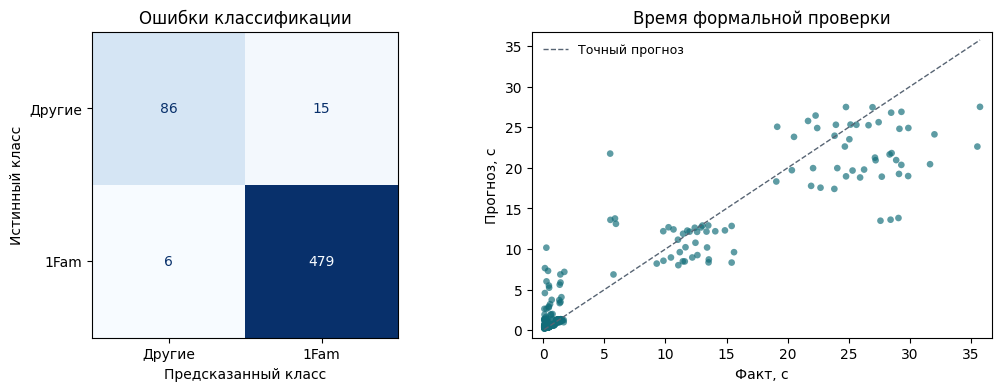

Другие типы, ошибочно отнесённые к 1Fam: 15 из 101.
Классовые прогнозы своей модели и sklearn расходятся на 0 из 586 домов.
Наибольшая абсолютная ошибка sklearn: 16.29 с (факт 5.47, прогноз 21.76, номер наблюдения = 1416).


In [16]:
# Находим ошибки по классам, максимальную ошибку длительности и расхождение реализаций.
plot_predictions(samples, lib_pred)
sample = samples["classification"]
truth = sample.y[sample.test]
missed = ((truth == 0) & (lib_pred["classification"] == 1)).sum()
disagreements = np.sum(lib_pred["classification"] != own_pred["classification"])
print(f"Другие типы, ошибочно отнесённые к 1Fam: {missed} из {(truth == 0).sum()}.")
print(f"Классовые прогнозы своей модели и sklearn расходятся на {disagreements} из {len(truth)} домов.")
sample = samples["regression"]
truth = sample.y[sample.test]
pred = lib_pred["regression"]
idx = np.argmax(np.abs(pred - truth))
print(f"Наибольшая абсолютная ошибка sklearn: {abs(pred[idx] - truth[idx]):.2f} с "
      f"(факт {truth[idx]:.2f}, прогноз {pred[idx]:.2f}, номер наблюдения = {sample.identifiers[sample.test[idx]]}).")

## Выводы

In [17]:
# Сопоставляем реализации и сохраняем результаты в CSV.
def describe(results, cv):
    """Сравниваем стадии у каждой реализации и обе реализации при одинаковых настройках."""
    for task in TASKS:
        metric = PRIMARY[task]
        tab = results[results.task.eq(task)].pivot(index="implementation", columns="stage", values=metric)
        base, selected = tab.loc["sklearn", ["base", "selected"]]
        scratch_base, scratch_selected = tab.loc["own", ["base", "selected"]]
        direction = 1 if task == "classification" else -1
        delta = selected - base
        verdict = "улучшился" if direction * delta > 1e-9 else "ухудшился" if direction * delta < -1e-9 else "не изменился"
        vals = cv[cv.task.eq(task)]
        name = vals.loc[vals.selected, "configuration"].iloc[0]
        text = (f"**{TASK_NAME[task]}.** По CV выбрана конфигурация «{name}». "
                f"На тесте показатель {NAMES[metric]} у sklearn {verdict}: "
                f"{base:.4f} → {selected:.4f}. У собственной реализации: "
                f"{scratch_base:.4f} → {scratch_selected:.4f}. ")
        diff_base, diff_selected = scratch_base - base, scratch_selected - selected
        if max(abs(diff_base), abs(diff_selected)) < 1e-9:
            text += "По этой метрике результаты двух реализаций совпали в обоих режимах."
        else:
            text += (f"Разность «своя минус sklearn» составила {diff_base:+.4f} "
                     f"для базовой и {diff_selected:+.4f} для выбранной настройки.")
        display(Markdown(text))


def save_results(lab, results, cv):
    folder = ROOT / "results"
    folder.mkdir(exist_ok=True)
    results.to_csv(folder / f"lab_{lab}_metrics.csv", index=False)
    cv.to_csv(folder / f"lab_{lab}_cv.csv", index=False)

In [18]:
# Измеряем эффект подбора и сравниваем свои модели с библиотечными в обоих режимах.
describe(results, cv)
save_results(LAB, results, cv)

**Классификация.** По CV выбрана конфигурация «11 соседей, обратные веса и признаки». На тесте показатель macro-F1 у sklearn не изменился: 0.9349 → 0.9349. У собственной реализации: 0.9349 → 0.9349. По этой метрике результаты двух реализаций совпали в обоих режимах.

**Регрессия.** По CV выбрана конфигурация «11 соседей, обратные веса и признаки». На тесте показатель MAE у sklearn улучшился: 5.0719 → 1.5489. У собственной реализации: 5.4047 → 1.5679. Разность «своя минус sklearn» составила +0.3328 для базовой и +0.0190 для выбранной настройки.

На обучающих фолдах увеличение числа соседей само по себе снизило macro-F1 с 0,939 до 0,931. В сочетании с обратными весами и производными признаками оно дало 0,947. На тесте выигрыш этой комбинации проявился в регрессии: средняя ошибка sklearn сократилась более чем на три секунды. При дискретных лимитах и кодах лотов несколько проверок могут оказаться на одинаковом расстоянии от запроса, поэтому важен порядок выбора соседей на границе окрестности.

[Сводное сравнение всех пяти алгоритмов](06_summary.ipynb)